In [4]:
import sqlite3
import pandas as pd
import plotly.express as px

conn = sqlite3.connect("spotify_dashboard.db")

df= pd.read_sql("SELECT * from spotify_tracks",conn)
print(f"Loaded{len(df):,}songs")
df.head()

Loaded89,740songs


,track_id,artists,album_name,track_name,popularity,explicit,danceability,energy,key,loudness,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min,popularity_category
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,1,-6.746,...,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,3.84,Popular
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,1,-17.235,...,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2.49,Popular
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,0,-9.734,...,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,3.51,Popular
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,0,-18.515,...,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3.37,Popular
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,2,-9.681,...,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3.31,Hot


In [7]:
top10_songs = df.nlargest(10,"popularity")[["track_name","artists","popularity","track_genre"]]
print("Top 10 most popular songs")
top10_songs
df.head()

Top 10 most popular songs


,track_id,artists,album_name,track_name,popularity,explicit,danceability,energy,key,loudness,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min,popularity_category
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,1,-6.746,...,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,3.84,Popular
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,1,-17.235,...,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2.49,Popular
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,0,-9.734,...,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,3.51,Popular
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,0,-18.515,...,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3.37,Popular
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,2,-9.681,...,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3.31,Hot


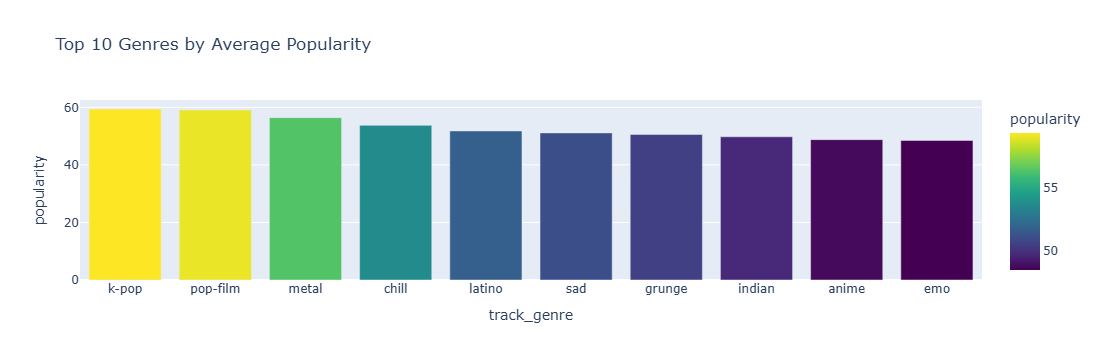

In [14]:
genre_popularity = df.groupby("track_genre")["popularity"].mean()\
.sort_values(ascending=False)\
.head(10)\
.reset_index()

fig = px.bar(
    genre_popularity,
    x="track_genre",
    y="popularity",
    title="Top 10 Genres by Average Popularity",
    color="popularity",
    color_continuous_scale="Viridis"
)
fig.show()

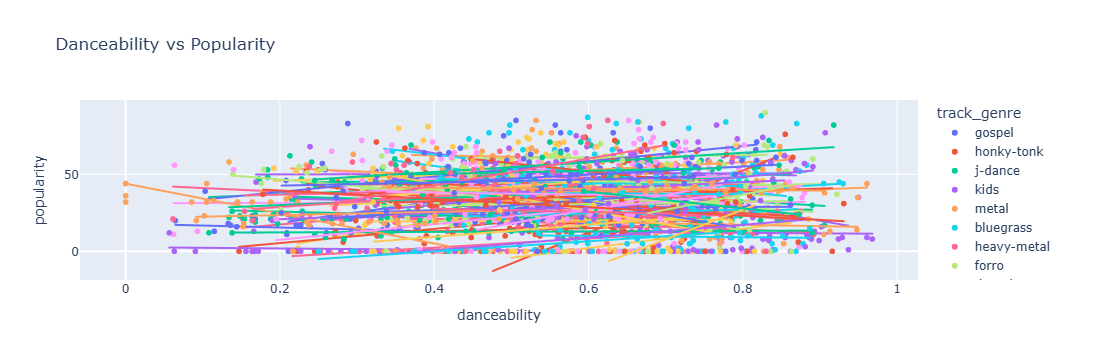

In [15]:
fig = px.scatter(
    df.sample(2000),
    x="danceability",
    y="popularity",
    title="Danceability vs Popularity",
    color="track_genre",
    hover_name="track_name",
    trendline="ols"
)
fig.show()

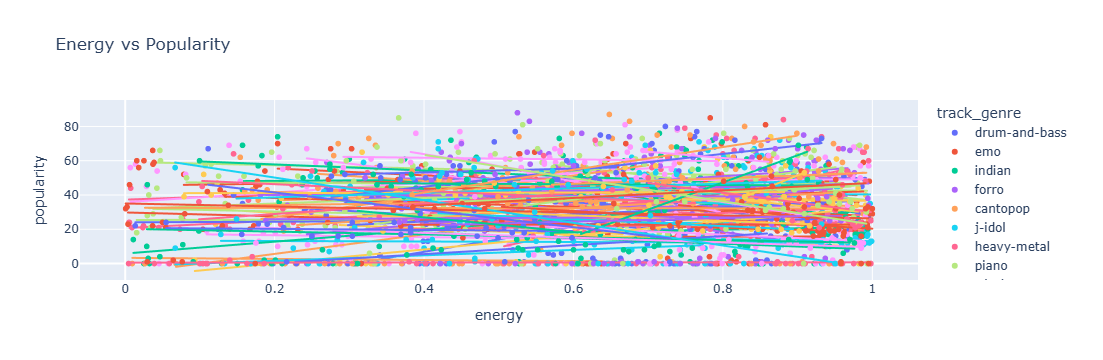

In [16]:
fig = px.scatter(
    df.sample(2000),
    x="energy",
    y="popularity",
    title="Energy vs Popularity",
    color="track_genre",
    hover_name="track_name",
    trendline="ols"
)
fig.show()

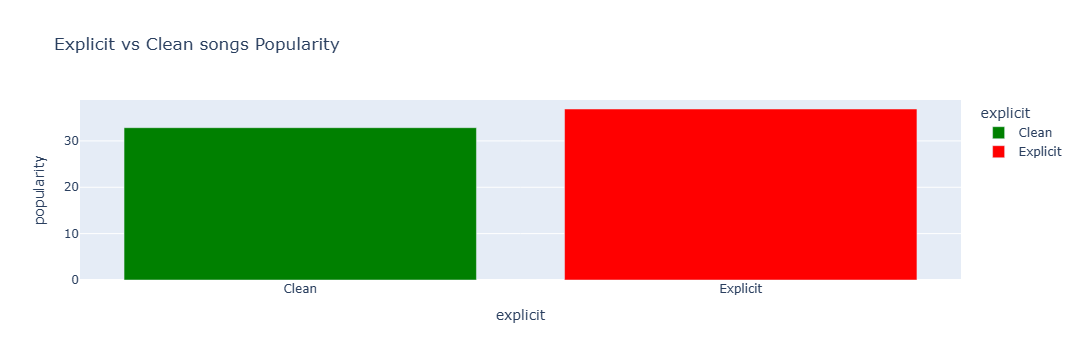

In [27]:
explicit_avg = df.groupby("explicit")["popularity"]\
.mean()\
.reset_index()

explicit_avg["explicit"] = explicit_avg["explicit"].map({1:"Explicit", 0:"Clean"})

fig = px.bar(
    explicit_avg,
    x="explicit",
    y="popularity",
    title="Explicit vs Clean songs Popularity",
    color="explicit",
    color_discrete_map={"Explicit": "red", "Clean": "green"}
)
fig.show()

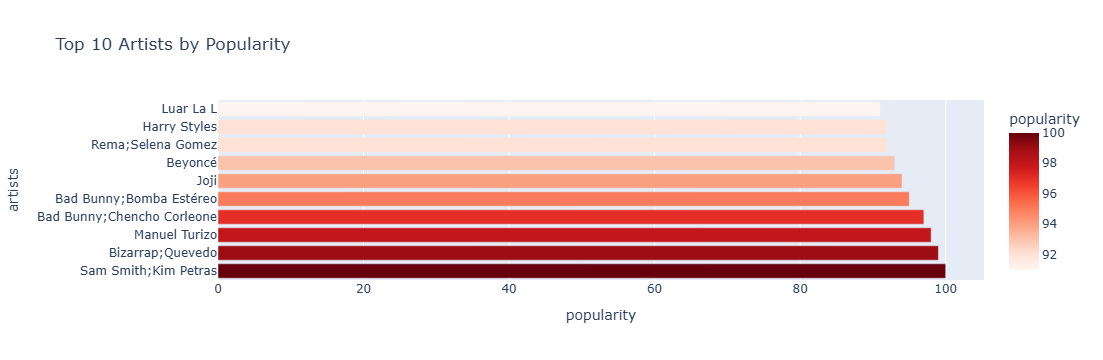

In [25]:
top_artists = df.groupby("artists")["popularity"]\
                .mean()\
                .sort_values(ascending=False)\
                .head(10)\
                .reset_index()

fig = px.bar(
    top_artists,
    x="popularity",
    y="artists",
    orientation="h",
    title="Top 10 Artists by Popularity",
    color="popularity",
    color_continuous_scale="Reds"
)
fig.show()

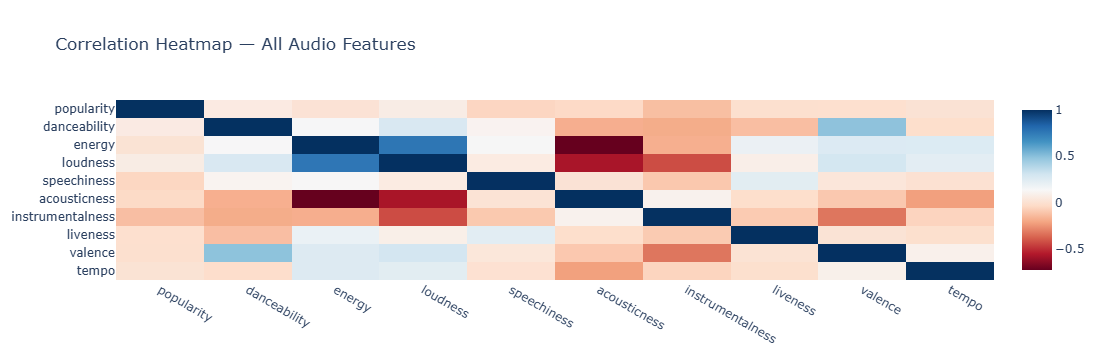

In [31]:
import plotly.figure_factory as ff
import numpy as np

numeric_cols = ["popularity", "danceability", "energy",
                "loudness", "speechiness", "acousticness",
                "instrumentalness", "liveness", 
                "valence", "tempo"]

corr = df[numeric_cols].corr().round(2)

fig = px.imshow(
    corr,
    title="Correlation Heatmap — All Audio Features",
    color_continuous_scale="RdBu",
    aspect="auto"
)
fig.show()

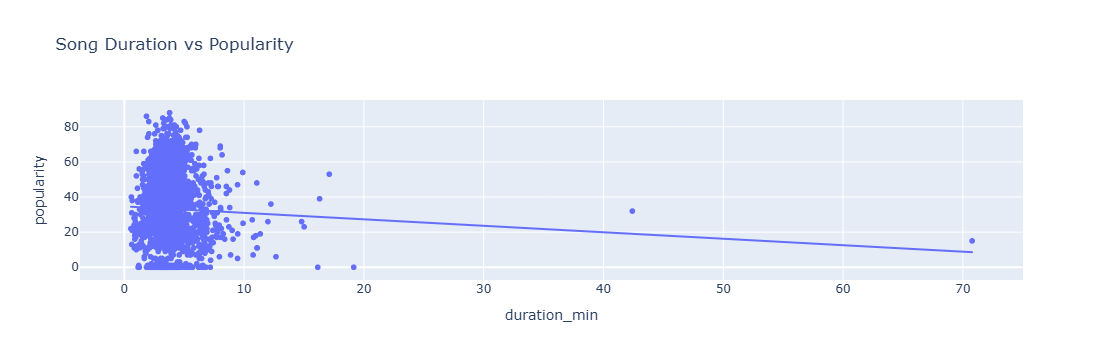

In [30]:
fig = px.scatter(
    df.sample(2000),
    x="duration_min",
    y="popularity",
    title="Song Duration vs Popularity",
    hover_name="track_name",
    trendline="ols"
)
fig.show()

In [32]:
print("="*50)
print(" KEY FINDINGS FROM ANALYSIS")
print("="*50)

print(f"\n Total Songs Analyzed: {len(df):,}")
print(f"\n Most Popular Genre: {genre_popularity.iloc[0]['track_genre']}")
print(f"\n Average Popularity: {df['popularity'].mean():.1f}/100")
print(f"\n Avg Danceability:   {df['danceability'].mean():.2f}/1.0")
print(f"\n Avg Energy:         {df['energy'].mean():.2f}/1.0")
print(f"\n Most Popular Artist: {top_artists.iloc[0]['artists']}")

corr_with_popularity = df[numeric_cols].corr()["popularity"]\
                       .drop("popularity")\
                       .sort_values(ascending=False)
print(f"\n Feature most correlated with popularity:")
print(f"   → {corr_with_popularity.index[0]}: {corr_with_popularity.iloc[0]:.3f}")

 KEY FINDINGS FROM ANALYSIS

 Total Songs Analyzed: 89,740

 Most Popular Genre: k-pop

 Average Popularity: 33.2/100

 Avg Danceability:   0.56/1.0

 Avg Energy:         0.63/1.0

 Most Popular Artist: Sam Smith;Kim Petras

 Feature most correlated with popularity:
   → loudness: 0.072
